图形已保存至: F:\TUB\greenlandProject\ERA5LAND\beifen\Picture\Greenland_Station_Classification.png


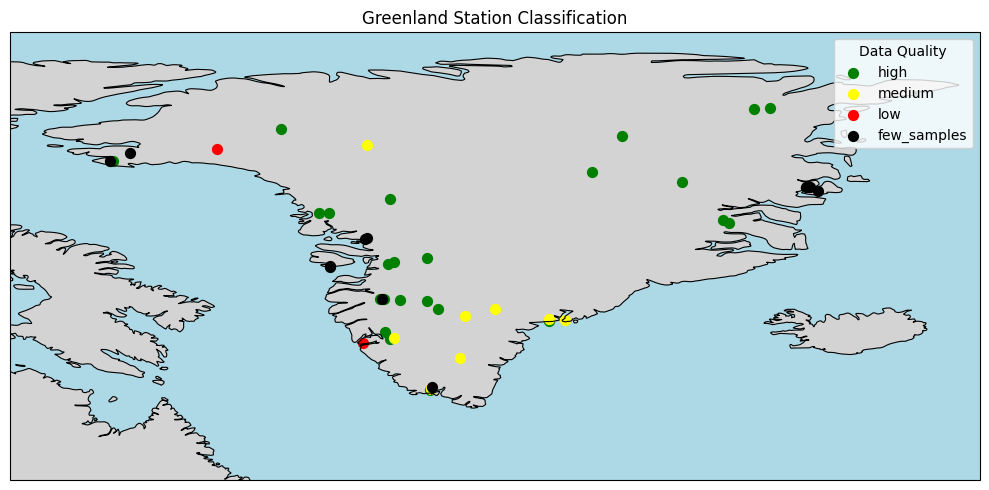

In [9]:
import matplotlib.pyplot as plt

# 站点数据
stations = {
    "CEN": (77.18, -61.12),
    "CP1": (69.87, -47.04),
    "DY2": (66.48, -46.29),
    "EGP": (75.63, -35.97),
    "FRE": (74.39, -20.83),
    "HUM": (78.53, -56.85),
    "JAR": (69.49, -49.67),
    "KAN_B": (67.13, -50.18),
    "KAN_L": (67.10, -49.93),
    "KAN_M": (67.07, -48.85),
    "KAN_T": (67.15, -50.04),
    "KAN_U": (67.00, -47.04),
    "KPC_L": (79.91, -24.09),
    "KPC_U": (79.83, -25.16),
    "LYN_L": (69.32, -53.54),
    "LYN_T": (69.30, -53.59),
    "MIT": (65.69, -37.83),
    "NAE": (75.00, -29.98),
    "NAU": (73.84, -49.54),
    "NEM": (77.44, -51.08),
    "NSE": (66.48, -42.49),
    "NUK_K": (64.16, -51.36),
    "NUK_L": (64.48, -49.56),
    "NUK_N": (64.95, -49.88),
    "NUK_U": (64.51, -49.29),
    "QAS_A": (61.24, -46.73),
    "QAS_L": (61.03, -46.85),
    "QAS_M": (61.11, -46.81),
    "QAS_U": (61.17, -46.82),
    "RED_L": (76.93, -66.96),
    "SCO_L": (72.22, -26.82),
    "SCO_U": (72.39, -27.21),
    "SDL": (66.00, -44.50),
    "SDM": (63.15, -44.82),
    "SWC": (69.59, -49.28),
    "TAS_A": (65.77, -38.89),
    "TAS_L": (65.64, -38.90),
    "TAS_U": (65.70, -38.87),
    "THU_L": (76.40, -68.27),
    "THU_L2": (76.39, -68.27),
    "THU_U": (76.39, -68.11),
    "TUN": (78.02, -33.96),
    "UPE_L": (72.89, -54.30),
    "UPE_U": (72.88, -53.62),
    "WEG_B": (71.14, -51.22),
    "WEG_L": (71.20, -51.10),
    "ZAC_A": (74.65, -21.65),
    "ZAC_L": (74.62, -21.37),
    "ZAC_U": (74.64, -21.46),
}

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 假设 stations 是包含经纬度信息的字典
# stations = {'CP1': (lat, lon), 'DY2': (lat, lon), ...}

# 手动定义数据质量分类
quality_dict = {
    # R² > 0.7 (高预测性能)
    'high': [
        'CP1', 'DY2', 'EGP', 'HUM', 'JAR', 'KAN_B', 'KAN_L', 'KAN_M', 'KAN_U',
        'KPC_L', 'KPC_U', 'NAE', 'NAU', 'NUK_L', 'NUK_N', 'QAS_L', 'SCO_L',
        'SCO_U', 'SWC', 'TAS_L', 'TAS_U', 'THU_L', 'THU_U', 'TUN', 'UPE_L', 'UPE_U'
    ],
    
    # R² ≈ 0.4–0.7 (中等预测性能)
    'medium': [
        'MIT', 'NEM', 'NSE', 'NUK_U', 'QAS_M', 'QAS_U', 'SDL', 'SDM', 'TAS_A'
    ],
    
    # R² < 0.4 (低预测性能)
    'low': [
        'CEN', 'NUK_K'
    ],
    
    # 样本数过少（<20）
    'few_samples': [
        'FRE', 'KAN_T', 'LYN_L', 'LYN_T', 'QAS_A', 'RED_L', 'THU_L2', 
        'WEG_B', 'WEG_L', 'ZAC_A', 'ZAC_L', 'ZAC_U'
    ]
}

# 颜色映射
color_map = {
    'high': 'green',
    'medium': 'yellow',
    'low': 'red',
    'few_samples': 'black'
}

# 创建图形和地理坐标轴
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# 添加地理特征
ax.add_feature(cfeature.LAND.with_scale('50m'), facecolor='lightgray')
ax.add_feature(cfeature.OCEAN.with_scale('50m'), facecolor='lightblue')
ax.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=0.8)
ax.add_feature(cfeature.BORDERS.with_scale('50m'), linestyle=':')

# 设置地图范围（格陵兰附近）
ax.set_extent([-75, -10, 55, 85], crs=ccrs.PlateCarree())

# 绘制站点
for quality, station_list in quality_dict.items():
    latitudes = [stations[s][0] for s in station_list if s in stations]
    longitudes = [stations[s][1] for s in station_list if s in stations]
    ax.scatter(longitudes, latitudes, 
               label=quality, 
               color=color_map[quality], 
               s=50, 
               edgecolors='face',
               transform=ccrs.PlateCarree())  # 确保使用正确的坐标转换

# 添加图例和标签
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Greenland Station Classification")
plt.legend(title="Data Quality")
plt.grid(True)
plt.tight_layout()

# 保存图形
output_path = r"F:\TUB\greenlandProject\ERA5LAND\beifen\Picture\Greenland_Station_Classification.png"
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"图形已保存至: {output_path}")

# 显示图形（可选）
plt.show()


In [3]:
# ----------------- 划分训练/验证集 --- 基础模型/堆叠 --- 评估 --- 保存3个PKL并打印绝对路径 ------------------
import os
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold
import xgboost as xgb
import lightgbm as lgb
import catboost
import joblib
from scipy.stats import pearsonr

# 读取和筛选数据（注意 Windows 路径使用原始字符串 r"" 以避免转义问题）
file_path = r"C:\greenland\merged_allfeature.csv"
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "asn", "year", "month"
]  # 删掉了 "sde" 的版本
target_column = "albedo"
exclude_stations = ["QAS_M", "MIT", "NUK_K"]

data = pd.read_csv(file_path)
data = data[~data["station"].isin(exclude_stations)]
data = data[data["year"] >= 1995]

if data.empty:
    raise RuntimeError("After filtering, no data remains for years >= 1995.")

X = data[input_features].astype(float)
y = data[target_column].astype(float)

# 拆分训练/测试集
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 定义基础模型（屏蔽训练时无关日志）
models = {
    'RF': RandomForestRegressor(n_estimators=500, n_jobs=-1, random_state=42),
    'XGB': xgb.XGBRegressor(
        n_estimators=500, n_jobs=-1, random_state=42,
        tree_method="hist", verbosity=0
    ),
    'GBDT': GradientBoostingRegressor(random_state=42),
    'LGBM': lgb.LGBMRegressor(
        n_estimators=1000, n_jobs=-1, random_state=42,
        verbose=-1  # 关键：屏蔽 LightGBM 的 [Info] 日志
    ),
    'CatBoost': catboost.CatBoostRegressor(
        iterations=1000, random_seed=42, verbose=0
    )
}

# 5折构造元特征（out-of-fold）
kf = KFold(n_splits=5, shuffle=True, random_state=42)
model_names = list(models.keys())
meta_features = np.zeros((X_train.shape[0], len(model_names)))

for j, name in enumerate(model_names):
    model = models[name]
    oof_pred = np.zeros(X_train.shape[0])
    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]
        model.fit(X_tr, y_tr)
        oof_pred[val_idx] = model.predict(X_val)
    meta_features[:, j] = oof_pred

# 元模型训练
meta_model = Ridge()
meta_model.fit(meta_features, y_train)

# 全量训练基础模型（用于最终预测）
trained_base_models = []
for name in model_names:
    m = models[name]
    m.fit(X_train, y_train)
    trained_base_models.append(m)

# 测试集堆叠预测
test_meta_features = np.column_stack([m.predict(X_test) for m in trained_base_models])
final_preds = meta_model.predict(test_meta_features)

# 模型评估（仅打印一条汇总，不打印训练库的详细日志）
r2 = r2_score(y_test, final_preds)
r, _ = pearsonr(y_test, final_preds)
mse = mean_squared_error(y_test, final_preds)
rmse = np.sqrt(mse)
print(f"R²: {r2:.6f}, R: {r:.6f}, RMSE: {rmse:.6f}, MSE: {mse:.6f}")

# ===== 保存模型：1) 整体堆叠 2) 仅基础模型 3) 仅元模型 =====
save_dir = os.path.abspath(os.getcwd())
prefix = "NoSdestacking_model"

stacking_model = {
    'trained_base_models': trained_base_models,
    'meta_model': meta_model,
    'base_model_names': model_names,  # 保留顺序，便于将来复现
    'input_features': input_features  # 方便推理时校验
}

path_all  = os.path.join(save_dir, f"{prefix}.pkl")
path_base = os.path.join(save_dir, f"{prefix}_base_models.pkl")
path_meta = os.path.join(save_dir, f"{prefix}_meta_model.pkl")

joblib.dump(stacking_model, path_all)
joblib.dump(trained_base_models, path_base)
joblib.dump(meta_model, path_meta)

print("Saved (all-in-one):", os.path.abspath(path_all))
print("Saved (base models):", os.path.abspath(path_base))
print("Saved (meta model):", os.path.abspath(path_meta))



R²: 0.883752, R: 0.940111, RMSE: 0.061686, MSE: 0.003805
Saved (all-in-one): C:\Users\11823\era5land\NoSdestacking_model.pkl
Saved (base models): C:\Users\11823\era5land\NoSdestacking_model_base_models.pkl
Saved (meta model): C:\Users\11823\era5land\NoSdestacking_model_meta_model.pkl


   conda remove -y xgboost
   conda clean --all -y
   conda install -c conda-forge xgboost -y
   

conda create -n xgboost_env python=3.8
conda activate xgboost_env
conda install -c conda-forge xgboost jupyter notebook pandas scikit-learn

In [12]:
import joblib
import pandas as pd
import numpy as np
import os
import warnings
import re

# 屏蔽一切警告
warnings.filterwarnings("ignore")

# 加载整体堆叠模型
stacking_model_path = r"C:\Users\11823\era5land\202209202402\NoSdestacking_model_Pre202209.pkl"
try:
    stacking_model = joblib.load(stacking_model_path)
    trained_base_models = stacking_model['trained_base_models']
    meta_model = stacking_model['meta_model']
    base_model_names = stacking_model['base_model_names']
    # input_features = stacking_model['input_features'] # 保持使用自定义的 input_features
except FileNotFoundError:
    print(f"❌ 错误：模型文件未找到于 {stacking_model_path}")
    exit()
except KeyError as e:
    print(f"❌ 错误：模型文件中缺少必要的键：{e}")
    exit()

# 输入特征
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "asn", "year", "sde", "month"
]
target_column = "albedo"

# 输入输出路径
input_folder = r"C:\greenland\ProcessedCSV"
output_folder = r"C:\Users\11823\era5land\202209202402"

# 创建输出文件夹（如不存在）
os.makedirs(output_folder, exist_ok=True)

# 设置要处理的年份范围（可修改）
start_year = 1950
end_year = 2024

# 分批处理大小
chunk_size = 1000

# 遍历所有文件
for filename in os.listdir(input_folder):
    # 提取年份（假设文件名中前4位是年份，如199507Greenland_allfeature.csv）
    match = re.match(r"(\d{4})\d{2}.*allfeature\.csv", filename)
    if match:
        year = int(match.group(1))
        
        # 构造预期的输出文件名
        file_prefix = filename.replace("allfeature.csv", "")
        output_file = os.path.join(output_folder, f"{file_prefix}prediction.csv")

        # --- 新增：检查预测结果文件是否已存在，如果存在则跳过 ---
        if os.path.exists(output_file):
            print(f"⏩ 文件 {filename} 的预测结果已存在于 {output_file}，跳过处理。")
            continue
        # --------------------------------------------------------

        if start_year <= year <= end_year:
            filepath = os.path.join(input_folder, filename)
            
            print(f"⏳ 开始处理文件: {filename}")
            
            try:
                # 优化：只读取需要的列，减少内存占用（如果 albedo 不在输入文件中，则不需要读取 target_column）
                # 原始文件中可能包含 target_column，但我们只用 input_features
                data = pd.read_csv(filepath, usecols=input_features) 
                # 重新读取完整的行，以便保留所有原始列和索引
                data_full = pd.read_csv(filepath) 
                data_input = data_full[input_features]


                all_results = []

                # 使用 iloc/loc 进行切片时，需要确保索引的对应性，这里使用完整的 data_full 和 data_input
                for start in range(0, len(data_input), chunk_size):
                    chunk_input = data_input.iloc[start:start + chunk_size]
                    chunk_full = data_full.iloc[start:start + chunk_size]
                    
                    # 找出非NaN的行索引
                    clean_indices = chunk_input.dropna().index
                    
                    # 确保索引非空
                    if clean_indices.empty:
                        continue

                    # 提取干净的数据块
                    chunk_clean_input = chunk_input.loc[clean_indices]
                    
                    # 使用干净的输入进行预测
                    base_preds = [model.predict(chunk_clean_input) for model in trained_base_models]
                    
                    # 检查 base_preds 是否为空，理论上不会如果 clean_indices 不为空
                    if not base_preds:
                        continue
                        
                    stacked_input = np.column_stack(base_preds)
                    final_preds = meta_model.predict(stacked_input)

                    # 在完整的行数据上，根据干净的索引进行切片
                    data_clean = chunk_full.loc[clean_indices].copy()
                    
                    # 将预测结果赋给 albedo 列
                    data_clean[target_column] = final_preds
                    all_results.append(data_clean)

                if all_results:
                    final_data = pd.concat(all_results, axis=0)
                    
                    # 检查 output_file 是否已被检查过（此处冗余，但作为双重保险）
                    if not os.path.exists(output_file):
                        final_data.to_csv(output_file, index=False)
                        print(f"✅ 文件 {output_file} 输出成功，共 {len(final_data)} 行")
                    else:
                        print(f"⚠️ 文件 {filename} 的预测结果已在检查期间生成，不再重复输出。")
                else:
                    print(f"⚠️ 文件 {filename} 没有有效数据，跳过")

            except Exception as e:
                print(f"❌ 处理文件 {filename} 出错：{e}")
                continue

⏩ 文件 195004allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195004prediction.csv，跳过处理。
⏩ 文件 195005allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195005prediction.csv，跳过处理。
⏩ 文件 195006allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195006prediction.csv，跳过处理。
⏩ 文件 195007allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195007prediction.csv，跳过处理。
⏩ 文件 195008allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195008prediction.csv，跳过处理。
⏩ 文件 195009allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195009prediction.csv，跳过处理。
⏩ 文件 195104allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195104prediction.csv，跳过处理。
⏩ 文件 195105allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195105prediction.csv，跳过处理。
⏩ 文件 195106allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195106prediction.csv，跳过处理。
⏩ 文件 195107allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195107prediction.csv，跳过处理。


In [ ]:
#删掉了 "sde",的版本 用于验证sde的影响，后证明没有影响
# 文件 C:\greenland\NosdePrediction\202208prediction.csv 输出成功，共 82482 行
#✅ 文件 C:\greenland\NosdePrediction\202209prediction.csv 输出成功，共 82482 行
#✅ 文件 C:\greenland\NosdePrediction\202304prediction.csv 输出成功，共 82482 行

In [ ]:
#裁剪-------------greenland区域--------------
import os
import pandas as pd

# 1. 读取边界经纬度点文件路径
boundary_file = r"F:\TUB\greenlandProject\ne_10m_admin_0_countries\GreenlandBoundryBu.csv"
input_dir = r"F:\TUB\greenlandProject\ERA5LAND\MonthlyFeatures\1995prediction"
output_dir = input_dir  # 保存到原目录，文件名加_clip

print("开始读取边界文件...")
boundary_df = pd.read_csv(boundary_file)
print(f"边界文件加载完成，读取到 {len(boundary_df)} 条经纬度点。")

# 确认列名
assert 'latitude' in boundary_df.columns and 'longitude' in boundary_df.columns, "边界文件缺少latitude或longitude列！"

# 用集合存储边界点，方便快速查找
boundary_coords = set(zip(boundary_df['latitude'], boundary_df['longitude']))
print(f"边界点转换为集合，便于快速匹配。")

# 遍历所有csv文件
files = [f for f in os.listdir(input_dir) if f.endswith('.csv') and not f.endswith('_clip.csv')]
print(f"待处理文件共计 {len(files)} 个。")

for filename in files:
    # 检查输出文件是否已存在
    new_filename = filename.replace('.csv', '_clip.csv')
    new_filepath = os.path.join(output_dir, new_filename)
    
    if os.path.exists(new_filepath):
        print(f"\n跳过文件: {filename}，裁剪后的文件已存在。")
        continue
    
    print(f"\n处理文件: {filename}")
    filepath = os.path.join(input_dir, filename)
    df = pd.read_csv(filepath)
    print(f"原文件行数: {len(df)}")

    # 检查列名
    if 'latitude' not in df.columns or 'longitude' not in df.columns:
        print(f"跳过文件 {filename}，缺少latitude或longitude列。")
        continue

    coords = list(zip(df['latitude'], df['longitude']))

    # 建立mask，只有边界集合中存在的点才保留
    mask = [coord in boundary_coords for coord in coords]
    clipped_df = df[mask]

    print(f"筛选后保留行数: {len(clipped_df)}")

    # 保存新文件
    clipped_df.to_csv(new_filepath, index=False)
    print(f"保存文件: {new_filename}")

print("\n所有文件处理完成。")


In [6]:
import os
import glob
import pandas as pd
import numpy as np
from datetime import datetime
from scipy import stats

folder_path = r"F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\1995bu"
pattern = os.path.join(folder_path, "*.csv")
file_list = sorted(glob.glob(pattern))

albedo_means = []
dates = []
monthly_data = {}  # 用于存储每月数据

for file in file_list:
    # 读取csv
    df = pd.read_csv(file)
    # 计算albedo均值
    mean_albedo = df['albedo'].mean()
    albedo_means.append(mean_albedo)
    
    # 从文件名提取时间，假设格式为：YYYYMMprediction_clip.csv，比如199004prediction_clip.csv
    basename = os.path.basename(file)
    date_str = basename[:6]  # 前6位 YYYYMM
    date_obj = datetime.strptime(date_str, "%Y%m")
    dates.append(date_obj)
    
    # 存储每月数据
    month_key = date_obj.strftime("%Y-%m")
    monthly_data[month_key] = mean_albedo

# 转换为DataFrame便于分析
df_albedo = pd.DataFrame({
    'date': dates,
    'albedo_mean': albedo_means
})
df_albedo['year'] = df_albedo['date'].dt.year
df_albedo['month'] = df_albedo['date'].dt.month

# 保存均值数据到同一路径下的mean.csv
output_path = os.path.join(folder_path, "mean.csv")
df_albedo.to_csv(output_path, index=False)
print(f"均值数据已保存到: {output_path}")

# 只输出最大值、最小值和均值
print("\n===== 统计分析结果 =====")
overall_mean = np.mean(albedo_means)
min_value = np.min(albedo_means)
max_value = np.max(albedo_means)
min_date = dates[np.argmin(albedo_means)].strftime('%Y-%m')
max_date = dates[np.argmax(albedo_means)].strftime('%Y-%m')

print(f"总体均值: {overall_mean:.4f}")
print(f"最小值: {min_value:.4f} (出现在 {min_date})")
print(f"最大值: {max_value:.4f} (出现在 {max_date})")

# 趋势分析
x = np.arange(len(albedo_means))
slope, intercept, r_value, p_value, std_err = stats.linregress(x, albedo_means)

print(f"\n===== 趋势分析 =====")
print(f"趋势斜率: {slope:.6f}")
print(f"R平方值: {r_value**2:.4f}")
print(f"P值: {p_value:.4f}")

if p_value < 0.05:
    if slope > 0:
        trend_description = "显著上升趋势"
    else:
        trend_description = "显著下降趋势"
else:
    trend_description = "无显著趋势"

print(f"趋势判断: {trend_description}")

# 季节性分析
seasonal_means = df_albedo.groupby('month')['albedo_mean'].mean()
print(f"\n===== 季节性分析 =====")
print(f"春季均值 (3-5月): {seasonal_means[3:6].mean():.4f}")
print(f"夏季均值 (6-8月): {seasonal_means[6:9].mean():.4f}")
print(f"秋季均值 (9-11月): {seasonal_means[9:12].mean():.4f}")
if len(seasonal_means) >= 12:
    winter_mean = pd.concat([seasonal_means[12:], seasonal_means[1:3]]).mean()
    print(f"冬季均值 (12,1-2月): {winter_mean:.4f}")

# 年度变化分析（如果跨越多年）
if len(df_albedo['year'].unique()) > 1:
    yearly_means = df_albedo.groupby('year')['albedo_mean'].mean()
    print(f"\n===== 年度变化 =====")
    for year, mean_val in yearly_means.items():
        print(f"{year}年均值: {mean_val:.4f}")

均值数据已保存到: F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\1995bu\mean.csv

===== 统计分析结果 =====
总体均值: 0.7565
最小值: 0.6728 (出现在 2012-07)
最大值: 0.8410 (出现在 2019-04)

===== 趋势分析 =====
趋势斜率: 0.000009
R平方值: 0.0008
P值: 0.5429
趋势判断: 无显著趋势

===== 季节性分析 =====
春季均值 (3-5月): 0.7236
夏季均值 (6-8月): nan
秋季均值 (9-11月): nan

===== 年度变化 =====
1950年均值: 0.7509
1951年均值: 0.7564
1952年均值: 0.7545
1953年均值: 0.7562
1954年均值: 0.7531
1955年均值: 0.7584
1956年均值: 0.7594
1957年均值: 0.7460
1958年均值: 0.7572
1959年均值: 0.7572
1960年均值: 0.7488
1961年均值: 0.7545
1962年均值: 0.7574
1963年均值: 0.7613
1964年均值: 0.7620
1965年均值: 0.7575
1966年均值: 0.7550
1967年均值: 0.7572
1968年均值: 0.7551
1969年均值: 0.7542
1970年均值: 0.7599
1971年均值: 0.7477
1972年均值: 0.7608
1973年均值: 0.7586
1974年均值: 0.7561
1975年均值: 0.7610
1976年均值: 0.7581
1977年均值: 0.7576
1978年均值: 0.7542
1979年均值: 0.7548
1980年均值: 0.7500
1981年均值: 0.7549
1982年均值: 0.7515
1983年均值: 0.7603
1984年均值: 0.7556
1985年均值: 0.7518
1986年均值: 0.7550
1987年均值: 0.7509
1988年均值: 0.7552
1989年均值: 0.7518
1990年均值: 0.7450
1991年均值

In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split, KFold
import xgboost as xgb
import lightgbm as lgb
import catboost
import shap
import matplotlib.pyplot as plt
import joblib
import os
from datetime import datetime

# ========== 1. 读取数据 ==========
file_path = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"
]
target_column = "albedo"
exclude_stations = ["QAS_M", "MIT", "NUK_K"]

data = pd.read_csv(file_path)
data = data[~data["station"].isin(exclude_stations)]

X = data[input_features].astype(float)
y = data[target_column]

# 检查缺失特征
missing_features = set(input_features) - set(data.columns)
if missing_features:
    raise ValueError(f"Missing features in data: {missing_features}")

# 拆分训练 / 测试集
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ========== 2. 定义基础模型 ==========
models = {
    'RF': RandomForestRegressor(n_jobs=-1, random_state=42),
    'XGB': xgb.XGBRegressor(n_jobs=-1, random_state=42),
    'GBDT': GradientBoostingRegressor(random_state=42),
    'LGBM': lgb.LGBMRegressor(n_jobs=-1, random_state=42),
    'CatBoost': catboost.CatBoostRegressor(verbose=0, random_seed=42)
}

# ========== 3. 构造元特征 (K折) ==========
kf = KFold(n_splits=5, shuffle=True, random_state=42)
meta_features = np.zeros((X_train.shape[0], len(models)))
model_statistics = {}

for idx, (name, model) in enumerate(models.items()):
    meta_feature = np.zeros(X_train.shape[0])

    for train_idx, val_idx in kf.split(X_train):
        X_t, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_t, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        model.fit(X_t, y_t)
        preds = model.predict(X_val)
        meta_feature[val_idx] = preds

    meta_features[:, idx] = meta_feature

    # CV指标
    r2 = r2_score(y_train, meta_feature)
    r, _ = pearsonr(y_train, meta_feature)
    mse = mean_squared_error(y_train, meta_feature)
    rmse = np.sqrt(mse)
    bias = np.mean(meta_feature - y_train)
    model_statistics[name] = {"R2": r2, "R": r, "RMSE": rmse, "MSE": mse, "Bias": bias}

# ========== 4. 训练元模型 ==========
meta_model = Ridge()
meta_model.fit(meta_features, y_train)

# ========== 5. 训练最终基础模型 ==========
trained_base_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_base_models[name] = model

# ========== 6. 测试集预测 ==========
test_meta_features = np.column_stack([
    trained_base_models[name].predict(X_test) for name in models
])
final_preds = meta_model.predict(test_meta_features)

# ========== 7. SHAP分析 ==========
shap_model = trained_base_models['RF']  # 用RF解释
try:
    explainer = shap.TreeExplainer(shap_model)
    shap_values = explainer.shap_values(X_test)

    plt.figure()
    shap.summary_plot(shap_values, X_test, show=False)
    plt.title("SHAP Summary (RF)")
    plt.tight_layout()
    plt.savefig("shap_summary_917.png")
    plt.close()

    plt.figure()
    shap.plots.bar(explainer(X_test), max_display=15, show=False)
    plt.title("Top 15 Features by SHAP Value")
    plt.tight_layout()
    plt.savefig("shap_bar_917.png")
    plt.close()
except Exception as e:
    print(f"⚠️ SHAP Error: {str(e)}")

# ========== 8. 输出性能 ==========
r2 = r2_score(y_test, final_preds)
r, _ = pearsonr(y_test, final_preds)
mse = mean_squared_error(y_test, final_preds)
rmse = np.sqrt(mse)
bias = np.mean(final_preds - y_test)

print("\n========== Final Stacking Model Test Evaluation ==========")
print(f"R²: {r2:.6f}")
print(f"Pearson R: {r:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"MSE: {mse:.6f}")
print(f"Bias: {bias:.6f}")

print("\n========== Base Model Cross-Validation Metrics ==========")
for name, stats in model_statistics.items():
    print(f"\n{name.upper()}:")
    for metric, value in stats.items():
        print(f"{metric}: {value:.6f}")

print("\n✅ 实际使用的特征:", list(X_train.columns))

# ========== 9. 保存模型 ==========
save_dir = "saved_models_917"
os.makedirs(save_dir, exist_ok=True)

# 保存基础模型
for name, model in trained_base_models.items():
    joblib.dump(model, os.path.join(save_dir, f"{name}_917.pkl"))

# 保存元模型
joblib.dump(meta_model, os.path.join(save_dir, "meta_model_917.pkl"))

print(f"\n✅ 模型已保存到 {save_dir}")


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000281 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2629
[LightGBM] [Info] Number of data points in the train set: 2695, number of used features: 15
[LightGBM] [Info] Start training from score 0.727292
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000149 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2645
[LightGBM] [Info] Number of data points in the train set: 2695, number of used features: 15
[LightGBM] [Info] Start training from score 0.726925
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000169 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2623
[LightGBM] [Info] Number of data points in the train set: 

正在读取数据...
原始数据形状: (4455, 17)
排除站点后数据形状: (4212, 17)
特征缺失值数量: 0
目标变量缺失值数量: 0
清除缺失值后数据形状: (4212, 15)

开始 Sample-based 验证...
训练集大小: (3369, 15), 测试集大小: (843, 15)
训练 RF...
训练 XGB...
训练 GBDT...
训练 LGBM...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000384 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2649
[LightGBM] [Info] Number of data points in the train set: 3369, number of used features: 15
[LightGBM] [Info] Start training from score 0.726634
训练 CatBoost...
Sample-based 验证结果:
R = 0.937, R² = 0.875, MAE = 0.041, RMSE = 0.065, N = 843

开始 Site-based 验证 (其他站点训练 → 预测TAS_L站点)...
目标站点: TAS_L
非目标站点: ['CEN', 'CP1', 'DY2', 'EGP', 'FRE', 'HUM', 'JAR', 'KAN_B', 'KAN_L', 'KAN_M', 'KAN_T', 'KAN_U', 'KPC_L', 'KPC_U', 'LYN_L', 'LYN_T', 'NAE', 'NAU', 'NEM', 'NSE', 'NUK_L', 'NUK_N', 'NUK_U', 'QAS_A', 'QAS_L', 'QAS_U', 'RED_L', 'SCO_L', 'SCO_U', 'SDL', 'SDM', 'SWC', 'TAS_A', 'TAS_U', 'THU_L2', 'THU_L', 'THU_U', '

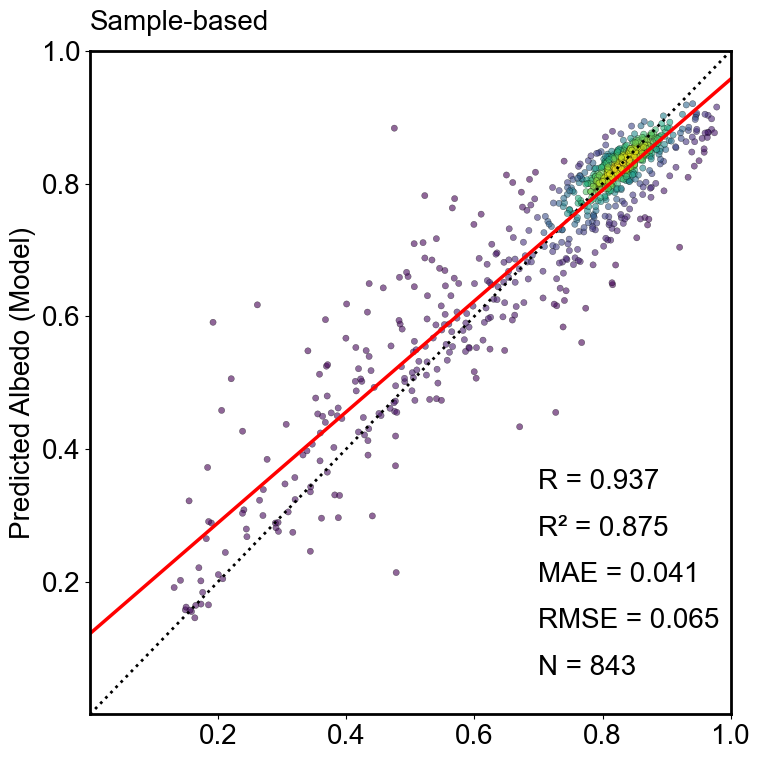

绘制 Site-based 散点图...


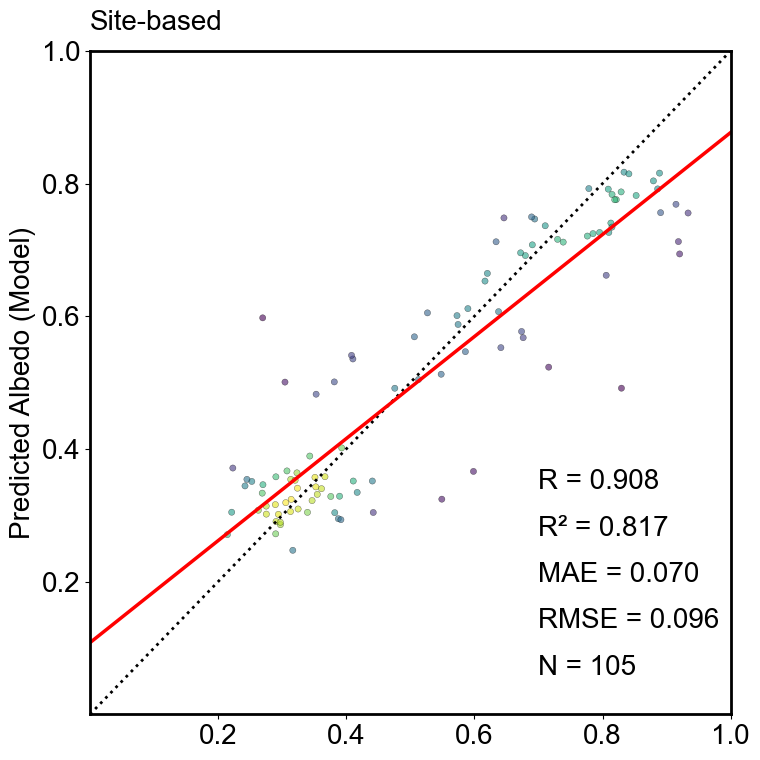


✅ 完成！已生成两个散点图:
1. Sample-based - 20%随机验证集
2. Site-based - 用其他站点训练，预测TAS_L站点


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, gaussian_kde
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.base import clone
import xgboost as xgb
import lightgbm as lgb
import catboost

# ========== 1. 读取数据 ==========
file_path = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"
]
target_column = "albedo"
exclude_stations = ["QAS_M", "MIT", "NUK_K"]

print("正在读取数据...")
data = pd.read_csv(file_path)
print(f"原始数据形状: {data.shape}")

# 排除指定站点
data = data[~data["station"].isin(exclude_stations)]
print(f"排除站点后数据形状: {data.shape}")

# 准备特征和目标
X = data[input_features].astype(float)
y = data[target_column]
stations = data["station"]

# 检查缺失值
print(f"特征缺失值数量: {X.isnull().sum().sum()}")
print(f"目标变量缺失值数量: {y.isnull().sum()}")

# 清除缺失值
mask = ~y.isnull() & ~X.isnull().any(axis=1)
X = X[mask]
y = y[mask]
stations = stations[mask]
data_clean = data[mask].copy()
print(f"清除缺失值后数据形状: {X.shape}")

# ========== 2. 定义模型 ==========
models = {
    'RF': RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42),
    'XGB': xgb.XGBRegressor(n_estimators=100, n_jobs=-1, random_state=42),
    'GBDT': GradientBoostingRegressor(n_estimators=100, random_state=42),
    'LGBM': lgb.LGBMRegressor(n_estimators=100, n_jobs=-1, random_state=42),
    'CatBoost': catboost.CatBoostRegressor(iterations=100, verbose=0, random_seed=42)
}

# ========== 3. Sample-based 验证 (20%随机划分) ==========
print("\n开始 Sample-based 验证...")
X_train, X_test, y_train, y_test, stations_train, stations_test = train_test_split(
    X, y, stations, test_size=0.2, random_state=42
)

print(f"训练集大小: {X_train.shape}, 测试集大小: {X_test.shape}")

# 训练基础模型
trained_models = {}
for name, model in models.items():
    print(f"训练 {name}...")
    model.fit(X_train, y_train)
    trained_models[name] = model

# 生成测试集预测
test_predictions = np.column_stack([
    model.predict(X_test) for model in trained_models.values()
])

# 使用简单平均作为最终预测
sample_based_pred = np.mean(test_predictions, axis=1)

# 计算统计指标
r_sample, _ = pearsonr(y_test, sample_based_pred)
r2_sample = r2_score(y_test, sample_based_pred)
mae_sample = mean_absolute_error(y_test, sample_based_pred)
rmse_sample = np.sqrt(mean_squared_error(y_test, sample_based_pred))
n_sample = len(y_test)

print(f"Sample-based 验证结果:")
print(f"R = {r_sample:.3f}, R² = {r2_sample:.3f}, MAE = {mae_sample:.3f}, RMSE = {rmse_sample:.3f}, N = {n_sample}")

# ========== 4. Site-based 验证 (用其他站点训练，预测TAS_L站点) ==========
print("\n开始 Site-based 验证 (其他站点训练 → 预测TAS_L站点)...")

# 识别TAS_L站点
all_stations = data_clean['station'].unique()
target_station = "TAS_L"
non_target_stations = [station for station in all_stations if station != target_station]

print(f"目标站点: {target_station}")
print(f"非目标站点: {non_target_stations}")
print(f"目标站点数量: 1, 非目标站点数量: {len(non_target_stations)}")

# 存储TAS_L站点的预测结果
target_true = []
target_pred = []

print(f"处理目标站点: {target_station}")

# 划分数据：非TAS_L站点作为训练集，TAS_L站点作为测试集
train_mask = data_clean['station'].isin(non_target_stations)
test_mask = data_clean['station'] == target_station

X_train_site = X[train_mask]
y_train_site = y[train_mask]
X_test_site = X[test_mask]
y_test_site = y[test_mask]

print(f"  训练集: {X_train_site.shape}, 测试集: {X_test_site.shape}")

if len(X_test_site) == 0:
    print(f"  ⚠️  {target_station} 没有数据，使用第一个站点作为示例")
    # 如果没有TAS_L站点，使用第一个站点作为示例
    first_station = all_stations[0]
    print(f"使用 {first_station} 作为测试站点进行演示...")
    
    train_mask = data_clean['station'] != first_station
    test_mask = data_clean['station'] == first_station
    
    X_train_site = X[train_mask]
    y_train_site = y[train_mask]
    X_test_site = X[test_mask]
    y_test_site = y[test_mask]
    
    trained_models_site = {}
    for name, model in models.items():
        model_clone = clone(model)
        model_clone.fit(X_train_site, y_train_site)
        trained_models_site[name] = model_clone
    
    test_predictions_site = np.column_stack([
        model.predict(X_test_site) for model in trained_models_site.values()
    ])
    target_pred = np.mean(test_predictions_site, axis=1)
    target_true = y_test_site
    
else:
    # 用非TAS_L站点训练模型
    trained_models_site = {}
    for name, model in models.items():
        model_clone = clone(model)
        model_clone.fit(X_train_site, y_train_site)
        trained_models_site[name] = model_clone
    
    # 生成预测并简单平均
    test_predictions_site = np.column_stack([
        model.predict(X_test_site) for model in trained_models_site.values()
    ])
    target_pred = np.mean(test_predictions_site, axis=1)
    target_true = y_test_site

target_true = np.array(target_true)
target_pred = np.array(target_pred)

# 计算统计指标
r_site, _ = pearsonr(target_true, target_pred)
r2_site = r2_score(target_true, target_pred)
mae_site = mean_absolute_error(target_true, target_pred)
rmse_site = np.sqrt(mean_squared_error(target_true, target_pred))
n_site = len(target_true)

print(f"Site-based 验证结果:")
print(f"R = {r_site:.3f}, R² = {r2_site:.3f}, MAE = {mae_site:.3f}, RMSE = {rmse_site:.3f}, N = {n_site}")

# ========== 5. 绘制 Sample-based 散点图 ==========
print("\n绘制 Sample-based 散点图...")
plt.rcParams.update(plt.rcParamsDefault)
font_size = 20

plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': font_size,
    'axes.titlesize': font_size,
    'axes.labelsize': font_size,
    'xtick.labelsize': font_size,
    'ytick.labelsize': font_size,
    'legend.fontsize': font_size,
    'axes.linewidth': 2.0,  # 加粗四周框线
})

plt.figure(figsize=(8, 8))

# 绘制散点密度图
xy_sample = np.vstack([y_test, sample_based_pred])
z_sample = gaussian_kde(xy_sample)(xy_sample)

plt.scatter(y_test, sample_based_pred, c=z_sample, cmap='viridis', s=20, alpha=0.6, edgecolors='black', linewidths=0.3)

# 绘制1:1线和回归线
plot_min, plot_max = 0.0, 1.0
plt.plot([plot_min, plot_max], [plot_min, plot_max], color='black', linestyle=':', linewidth=2)
a_sample, b_sample = np.polyfit(y_test, sample_based_pred, 1)
x_line_sample = np.linspace(plot_min, plot_max, 100)
y_line_sample = a_sample * x_line_sample + b_sample
plt.plot(x_line_sample, y_line_sample, color='red', linestyle='-', linewidth=2.5)

# 设置坐标轴 - 删除重复的0.0刻度
plt.xlim(plot_min, plot_max)
plt.ylim(plot_min, plot_max)
# plt.xlabel("Station Albedo")  # 注释掉X轴标签
plt.ylabel("Predicted Albedo (Model)")
plt.title("Sample-based", loc='left', pad=15)

# 设置刻度 - 删除重复的0.0
xticks = [0.2, 0.4, 0.6, 0.8, 1.0]
yticks = [0.2, 0.4, 0.6, 0.8, 1.0]
plt.xticks(xticks)
plt.yticks(yticks)

# 添加统计信息 - 恢复R2显示
text_x_pos = 0.70
text_y_start = 0.35
line_spacing = 0.07

plt.text(text_x_pos, text_y_start, f'R = {r_sample:.3f}', transform=plt.gca().transAxes, ha='left', va='center', fontsize=font_size)
plt.text(text_x_pos, text_y_start - line_spacing, f'R² = {r2_sample:.3f}', transform=plt.gca().transAxes, ha='left', va='center', fontsize=font_size)
plt.text(text_x_pos, text_y_start - 2*line_spacing, f'MAE = {mae_sample:.3f}', transform=plt.gca().transAxes, ha='left', va='center', fontsize=font_size)
plt.text(text_x_pos, text_y_start - 3*line_spacing, f'RMSE = {rmse_sample:.3f}', transform=plt.gca().transAxes, ha='left', va='center', fontsize=font_size)
plt.text(text_x_pos, text_y_start - 4*line_spacing, f'N = {n_sample:,}', transform=plt.gca().transAxes, ha='left', va='center', fontsize=font_size)

plt.tight_layout()
plt.show()

# ========== 6. 绘制 Site-based 散点图 ==========
print("绘制 Site-based 散点图...")
plt.figure(figsize=(8, 8))

# 绘制散点密度图
xy_site = np.vstack([target_true, target_pred])
z_site = gaussian_kde(xy_site)(xy_site)

plt.scatter(target_true, target_pred, c=z_site, cmap='viridis', s=20, alpha=0.6, edgecolors='black', linewidths=0.3)

# 绘制1:1线和回归线
plt.plot([plot_min, plot_max], [plot_min, plot_max], color='black', linestyle=':', linewidth=2)
a_site, b_site = np.polyfit(target_true, target_pred, 1)
x_line_site = np.linspace(plot_min, plot_max, 100)
y_line_site = a_site * x_line_site + b_site
plt.plot(x_line_site, y_line_site, color='red', linestyle='-', linewidth=2.5)

# 设置坐标轴 - 删除重复的0.0刻度
plt.xlim(plot_min, plot_max)
plt.ylim(plot_min, plot_max)
# plt.xlabel("Station Albedo")  # 注释掉X轴标签
plt.ylabel("Predicted Albedo (Model)")
plt.title("Site-based", loc='left', pad=15)

# 设置刻度 - 删除重复的0.0
plt.xticks(xticks)
plt.yticks(yticks)

# 添加统计信息 - 恢复R2显示
plt.text(text_x_pos, text_y_start, f'R = {r_site:.3f}', transform=plt.gca().transAxes, ha='left', va='center', fontsize=font_size)
plt.text(text_x_pos, text_y_start - line_spacing, f'R² = {r2_site:.3f}', transform=plt.gca().transAxes, ha='left', va='center', fontsize=font_size)
plt.text(text_x_pos, text_y_start - 2*line_spacing, f'MAE = {mae_site:.3f}', transform=plt.gca().transAxes, ha='left', va='center', fontsize=font_size)
plt.text(text_x_pos, text_y_start - 3*line_spacing, f'RMSE = {rmse_site:.3f}', transform=plt.gca().transAxes, ha='left', va='center', fontsize=font_size)
plt.text(text_x_pos, text_y_start - 4*line_spacing, f'N = {n_site:,}', transform=plt.gca().transAxes, ha='left', va='center', fontsize=font_size)

plt.tight_layout()
plt.show()

print("\n✅ 完成！已生成两个散点图:")
print("1. Sample-based - 20%随机验证集")
print("2. Site-based - 用其他站点训练，预测TAS_L站点")

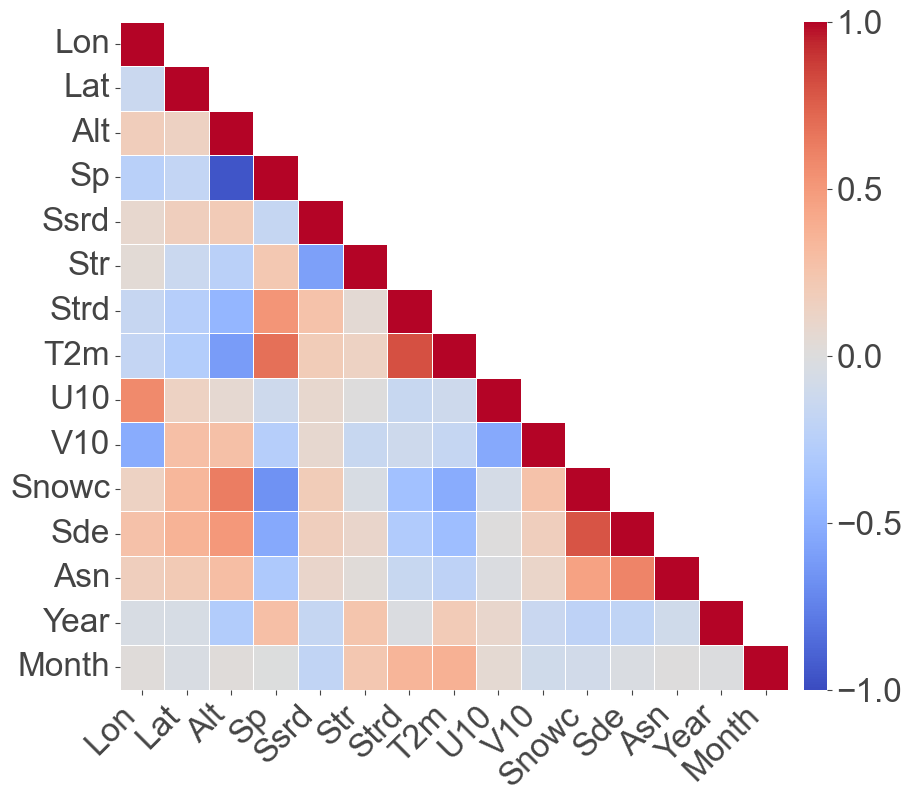

In [1]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ===== 路径 =====
file_path = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
df = pd.read_csv(file_path)

# ===== 特征列（简写 altitude）=====
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"
]
num_df = df[input_features].astype(float)
corr = num_df.corr(method='spearman')

# ===== 简写列名映射 =====
rename_dict = {
    'longitude': 'Lon',
    'latitude': 'Lat',
    'altitude_last_valid': 'Alt',
    'sp': 'Sp',
    'ssrd': 'Ssrd',
    'str': 'Str',
    'strd': 'Strd',
    't2m': 'T2m',
    'u10': 'U10',
    'v10': 'V10',
    'snowc': 'Snowc',
    'sde': 'Sde',
    'asn': 'Asn',
    'year': 'Year',
    'month': 'Month'
}

corr.rename(index=rename_dict, columns=rename_dict, inplace=True)

# ===== 遮上三角但保留对角线 =====
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

# ===== npj风格设置 =====
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 24,
    "axes.linewidth": 0.8,
    "axes.edgecolor": "black",
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.color": "#444444",
    "ytick.color": "#444444",
})

# ===== 绘制热力图 =====
fig, ax = plt.subplots(figsize=(9.5, 8))
sns.heatmap(
    corr, mask=mask,
    cmap="coolwarm", vmin=-1, vmax=1, center=0,
    square=True, annot=False,
    linewidths=0.4, linecolor="white",
    cbar_kws={
        "orientation": "vertical",
        "pad": 0.02,
        "shrink": 1.0,
        "aspect": 30,
        "ticks": [-1, -0.5, 0, 0.5, 1],
    },
    ax=ax
)

# ===== 美化标签 =====
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

# ===== 移除标题与图例文字 =====
cbar = ax.collections[0].colorbar
cbar.set_label("")
ax.set_title("")

# ===== 紧凑布局并保存 =====
plt.tight_layout(pad=0.3)
plt.savefig(r"C:\Users\11823\era5land\Fig_TriangularCorrelation_npJ_cleanFinal.png",
            dpi=400, bbox_inches='tight')
plt.show()

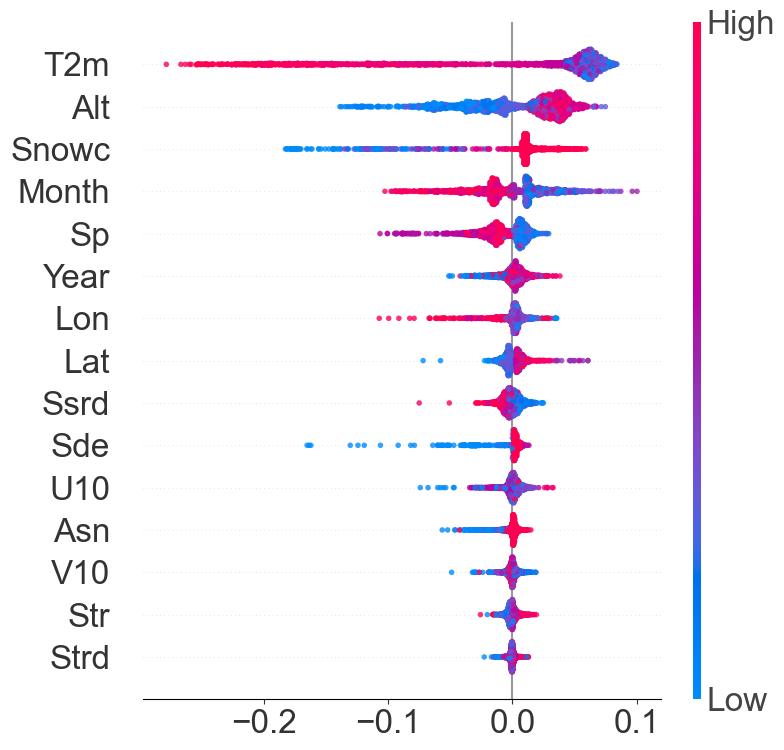

Saved to: C:\Users\11823\era5land\Fig_SHAP_npJstyle_font24_aligned.png


In [ ]:
# -*- coding: utf-8 -*-
import shap
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import joblib
import numpy as np

# ===== 载入数据与模型（与之前一致）=====
file_path = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
df = pd.read_csv(file_path)
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"
]
num_df = df[input_features].astype(float)

# 重命名列以简化显示
num_df.rename(columns={'altitude_last_valid': 'altitude'}, inplace=True)

# 加载你保存的基础模型（RF）以便做 SHAP
rf_model = joblib.load(r"C:\Users\11823\era5land\saved_models_917\RF_917.pkl")

# ===== 计算 SHAP =====
explainer = shap.TreeExplainer(rf_model)
sampled = num_df.sample(2000, random_state=42)
shap_values = explainer.shap_values(sampled)

# ===== npj 风格设置 =====
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 24,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.color": "#444444",
    "ytick.color": "#444444",
})

# ===== 颜色映射保持与热力图一致 =====
cmap = sns.color_palette("coolwarm", as_cmap=True)

# ===== 绘制 SHAP Summary Plot =====
plt.figure(figsize=(8, 7))
shap.summary_plot(
    shap_values, sampled,
    plot_type="dot",
    color=cmap,
    show=False,
    alpha=0.8
)

# ===== 删除 "Feature value" 颜色条标签 =====
cbar = plt.gcf().axes[-1]  # 获取colorbar
cbar.set_ylabel("")  # 删除 "Feature value" 文字

# ===== 去掉标题与额外文字，调整布局 =====
plt.title("")
plt.xlabel("SHAP value (impact on albedo prediction)", fontsize=24, labelpad=10)
plt.ylabel("")

# ===== 设置x轴刻度为 -0.2, -0.1, 0, 0.1 =====
plt.xticks([-0.2, -0.1, 0, 0.1])

# ===== 调整边框：删除y轴线，保留其他 =====
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)  # 删除y轴线
ax.spines["bottom"].set_visible(True)
ax.tick_params(left=False)  # 去掉y轴刻度线

plt.tight_layout(pad=0.3)

# ===== 保存图像 =====
plt.savefig(r"C:\Users\11823\era5land\Fig_SHAP_npJstyle.png",
            dpi=400, bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split, KFold
import xgboost as xgb
import lightgbm as lgb
import catboost

# 读取数据
file_path = "F:/TUB/greenlandProject/ERA5LAND/merged_allfeature.csv"
original_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"
]
target_column = "albedo"
exclude_stations = ["QAS_M", "MIT", "NUK_K"]

data = pd.read_csv(file_path)
data = data[~data["station"].isin(exclude_stations)]
y = data[target_column]

# 存储所有堆叠模型结果
stacking_results = []

# 轮询每个特征
for feature_to_remove in original_features:
    # 当前使用的特征
    current_features = [f for f in original_features if f != feature_to_remove]
    X = data[current_features].copy().astype(float)
    
    # 拆分训练测试集
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # 定义模型
    models = {
        'RF': RandomForestRegressor(n_jobs=-1, random_state=42),
        'XGB': xgb.XGBRegressor(n_jobs=-1, random_state=42),
        'GBDT': GradientBoostingRegressor(random_state=42),
        'LGBM': lgb.LGBMRegressor(n_jobs=-1, random_state=42),
        'CatBoost': catboost.CatBoostRegressor(verbose=0, random_seed=42)
    }

    # 构造元特征
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    meta_features = np.zeros((X_train.shape[0], len(models)))
    
    for idx, (name, model) in enumerate(models.items()):
        meta_feature = np.zeros(X_train.shape[0])
        for train_idx, val_idx in kf.split(X_train):
            X_t, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
            y_t, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
            model.fit(X_t, y_t)
            meta_feature[val_idx] = model.predict(X_val)
        meta_features[:, idx] = meta_feature

    # 元模型训练
    meta_model = Ridge()
    meta_model.fit(meta_features, y_train)

    # 全量训练基础模型
    trained_base_models = [model.fit(X_train, y_train) for model in models.values()]

    # 测试集堆叠预测
    test_meta_features = np.column_stack([model.predict(X_test) for model in trained_base_models])
    final_preds = meta_model.predict(test_meta_features)

    # 计算指标
    r2 = r2_score(y_test, final_preds)
    r, _ = pearsonr(y_test, final_preds)
    rmse = np.sqrt(mean_squared_error(y_test, final_preds))
    bias = np.mean(final_preds - y_test)

    stacking_results.append({
        "Removed Feature": feature_to_remove,
        "R2": r2,
        "Pearson R": r,
        "RMSE": rmse,
        "Bias": bias,
        "Remaining Features": len(current_features)
    })

# 输出结果
print("\n========== Stacking Model Results (Leave-One-Feature-Out) ==========")
print(f"{'Removed Feature':<20} {'R²':>8} {'Pearson R':>10} {'RMSE':>10} {'Bias':>10} {'Features':>10}")
print("-" * 80)
for result in stacking_results:
    print(f"{result['Removed Feature']:<20} {result['R2']:>8.4f} {result['Pearson R']:>10.4f} "
          f"{result['RMSE']:>10.4f} {result['Bias']:>10.4f} {result['Remaining Features']:>10}")

# 找出影响最大的特征
worst_r2 = min(stacking_results, key=lambda x: x['R2'])
print("\n⚠️ Most harmful feature to remove:", worst_r2['Removed Feature'])
print(f"   (R² dropped to {worst_r2['R2']:.4f} when removed)")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000328 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2583
[LightGBM] [Info] Number of data points in the train set: 2695, number of used features: 14
[LightGBM] [Info] Start training from score 0.727292
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000306 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2599
[LightGBM] [Info] Number of data points in the train set: 2695, number of used features: 14
[LightGBM] [Info] Start training from score 0.726925
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000258 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2577
[LightGBM] [Info] Number of data points in the train set: 

In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
import lightgbm as lgb
import catboost
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split, KFold
import optuna  # 需要安装: pip install optuna
import warnings

# 忽略过多的警告信息，保持输出整洁
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING) # 只显示关键信息

# ========== 1. 读取与预处理数据 (保持不变) ==========
file_path = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"
]
target_column = "albedo"
exclude_stations = ["QAS_M", "MIT", "NUK_K"]

print("正在读取数据...")
data = pd.read_csv(file_path)
data = data[~data["station"].isin(exclude_stations)]

X = data[input_features].astype(float)
y = data[target_column]

# 拆分训练 / 测试集 (固定随机种子以保证比较公平)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"数据准备完毕。训练集样本数: {len(X_train)}, 测试集样本数: {len(X_test)}")
print("开始 Optuna 自动调参 (比较不同参数下的堆叠模型效果)...\n")
print("-" * 100)
print(f"{'Trial ID':<10} | {'R2 Score':<10} | {'Pearson R':<10} | {'RMSE':<10} | {'Status'}")
print("-" * 100)

# ========== 2. 定义 Optuna 目标函数 ==========
def objective(trial):
    """
    每次 Trial 都会运行一次完整的 Stacking 流程
    """
    
    # --- A. 为各个基模型建议参数 (Search Space) ---
    
    # 1. RandomForest
    rf_n_estimators = trial.suggest_int("rf_n_estimators", 50, 300)
    rf_max_depth = trial.suggest_int("rf_max_depth", 5, 25)
    rf_min_samples_split = trial.suggest_int("rf_min_samples_split", 2, 10)
    
    # 2. XGBoost
    xgb_lr = trial.suggest_float("xgb_lr", 0.01, 0.3)
    xgb_depth = trial.suggest_int("xgb_depth", 3, 10)
    xgb_n_estimators = trial.suggest_int("xgb_n_estimators", 50, 300)
    
    # 3. GBDT (GradientBoosting)
    gbdt_lr = trial.suggest_float("gbdt_lr", 0.01, 0.3)
    gbdt_depth = trial.suggest_int("gbdt_depth", 3, 8)
    gbdt_n_estimators = trial.suggest_int("gbdt_n_estimators", 50, 300)
    
    # 4. LightGBM
    lgb_lr = trial.suggest_float("lgb_lr", 0.01, 0.3)
    lgb_num_leaves = trial.suggest_int("lgb_num_leaves", 20, 100)
    
    # 5. CatBoost
    cat_lr = trial.suggest_float("cat_lr", 0.01, 0.3)
    cat_depth = trial.suggest_int("cat_depth", 4, 10)
    cat_iterations = trial.suggest_int("cat_iterations", 100, 500)

    # 6. Meta Model (Ridge) Alpha
    ridge_alpha = trial.suggest_float("meta_ridge_alpha", 0.1, 10.0)

    # --- B. 实例化模型 ---
    models = {
        'RF': RandomForestRegressor(
            n_estimators=rf_n_estimators,
            max_depth=rf_max_depth,
            min_samples_split=rf_min_samples_split,
            n_jobs=-1, random_state=42
        ),
        'XGB': xgb.XGBRegressor(
            n_estimators=xgb_n_estimators,
            max_depth=xgb_depth,
            learning_rate=xgb_lr,
            n_jobs=-1, random_state=42
        ),
        'GBDT': GradientBoostingRegressor(
            n_estimators=gbdt_n_estimators,
            max_depth=gbdt_depth,
            learning_rate=gbdt_lr,
            random_state=42
        ),
        'LGBM': lgb.LGBMRegressor(
            num_leaves=lgb_num_leaves,
            learning_rate=lgb_lr,
            n_estimators=100, # 固定基础树数量，主要调叶子和学习率
            n_jobs=-1, random_state=42, verbose=-1
        ),
        'CatBoost': catboost.CatBoostRegressor(
            iterations=cat_iterations,
            learning_rate=cat_lr,
            depth=cat_depth,
            verbose=0, random_seed=42
        )
    }

    # --- C. Stacking: 构造元特征 (5-Fold CV) ---
    # 注意：为了速度，这里没有做内部早停(Early Stopping)，直接使用建议的轮数
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    meta_features_train = np.zeros((X_train.shape[0], len(models)))
    
    # 暂存训练好的模型以便后续在 Test 集预测
    # (在 Optuna 中每次都要重新训练，不能复用外部变量)
    trained_models = {} 

    # C1. 生成 Out-of-Fold 预测 (作为 Meta Model 的训练数据)
    for idx, (name, model) in enumerate(models.items()):
        oof_pred = np.zeros(X_train.shape[0])
        for train_idx, val_idx in kf.split(X_train):
            X_t, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
            y_t, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
            
            model.fit(X_t, y_t)
            oof_pred[val_idx] = model.predict(X_val)
        
        meta_features_train[:, idx] = oof_pred
        
        # 重新在全量训练集上训练一次，用于测试集预测
        model.fit(X_train, y_train)
        trained_models[name] = model

    # --- D. 训练元模型 ---
    meta_model = Ridge(alpha=ridge_alpha)
    meta_model.fit(meta_features_train, y_train)

    # --- E. 在测试集上评估 ---
    # 生成测试集的元特征
    test_meta_features = np.column_stack([
        trained_models[name].predict(X_test) for name in models
    ])
    
    final_preds = meta_model.predict(test_meta_features)

    # 计算指标
    r2 = r2_score(y_test, final_preds)
    r, _ = pearsonr(y_test, final_preds)
    mse = mean_squared_error(y_test, final_preds)
    rmse = np.sqrt(mse)

    # --- F. 打印当前 Trial 的结果 ---
    print(f"Trial {trial.number:<4} | {r2:.5f}     | {r:.5f}     | {rmse:.5f}     | OK")

    # Optuna 默认是最小化目标函数，这里我们返回 RMSE (越小越好)
    return rmse

# ========== 3. 运行优化 ==========
# n_trials 控制尝试多少组不同的参数。建议先跑 10-20 次看看效果。
# 在正式发文章时，建议 n_trials 设置为 50 或 100。
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=10) # 这里运行 10 次作为演示

# ========== 4. 输出最佳结果 ==========
print("-" * 100)
print("\n🏆 最佳 Trial 结果:")
best_trial = study.best_trial

print(f"  Trial ID: {best_trial.number}")
print(f"  最佳 RMSE: {best_trial.value:.6f}")
print("  最佳参数组合:")
for key, value in best_trial.params.items():
    print(f"    {key}: {value}")

print("\n⚠️ 注意: 该脚本仅用于参数比较，未保存模型。")
print("如需使用最佳参数，请将上述参数填入原训练代码，或要求我生成使用最佳参数的训练脚本。")

正在读取数据...
数据准备完毕。训练集样本数: 3369, 测试集样本数: 843
开始 Optuna 自动调参 (比较不同参数下的堆叠模型效果)...

----------------------------------------------------------------------------------------------------
Trial ID   | R2 Score   | Pearson R  | RMSE       | Status
----------------------------------------------------------------------------------------------------
Trial 0    | 0.87440     | 0.93538     | 0.06519     | OK
Trial 1    | 0.88346     | 0.94043     | 0.06279     | OK
Trial 2    | 0.87862     | 0.93813     | 0.06408     | OK
Trial 3    | 0.87878     | 0.93812     | 0.06404     | OK
Trial 4    | 0.87265     | 0.93509     | 0.06564     | OK
Trial 5    | 0.87020     | 0.93390     | 0.06627     | OK
Trial 6    | 0.87832     | 0.93802     | 0.06416     | OK
Trial 7    | 0.87789     | 0.93768     | 0.06428     | OK
Trial 8    | 0.88288     | 0.94012     | 0.06295     | OK
Trial 9    | 0.88491     | 0.94111     | 0.06240     | OK
--------------------------------------------------------------------------------

In [2]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split, KFold
import xgboost as xgb
import lightgbm as lgb
import catboost
import shap
import matplotlib.pyplot as plt
import joblib
import os

# ========== 1. 读取数据 (保持一致) ==========
file_path = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"
]
target_column = "albedo"
exclude_stations = ["QAS_M", "MIT", "NUK_K"]

print("正在读取数据...")
data = pd.read_csv(file_path)
data = data[~data["station"].isin(exclude_stations)]

X = data[input_features].astype(float)
y = data[target_column]

# 拆分训练 / 测试集 (必须保持 random_state=42 以复现 Optuna 的结果)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ========== 2. 定义模型 (使用 Optuna Trial 9 的最佳参数) ==========
print("正在初始化优化后的模型...")

models = {
    'RF': RandomForestRegressor(
        n_estimators=164,
        max_depth=25,
        min_samples_split=9,
        n_jobs=-1, 
        random_state=42
    ),
    'XGB': xgb.XGBRegressor(
        learning_rate=0.1858113937472557,
        max_depth=6,
        n_estimators=292,
        n_jobs=-1, 
        random_state=42
    ),
    'GBDT': GradientBoostingRegressor(
        learning_rate=0.2574136275826639,
        max_depth=4,
        n_estimators=143,
        random_state=42
    ),
    'LGBM': lgb.LGBMRegressor(
        learning_rate=0.2593889320092145,
        num_leaves=32,
        n_estimators=100, # 保持基础设定
        n_jobs=-1, 
        random_state=42,
        verbose=-1
    ),
    'CatBoost': catboost.CatBoostRegressor(
        learning_rate=0.23540974207333726,
        depth=6,
        iterations=364,
        verbose=0, 
        random_seed=42
    )
}

# ========== 3. 构造元特征 (Stacking) ==========
print("开始 Stacking (5-Fold Cross Validation)...")
kf = KFold(n_splits=5, shuffle=True, random_state=42)
meta_features = np.zeros((X_train.shape[0], len(models)))
model_statistics = {}

for idx, (name, model) in enumerate(models.items()):
    print(f"  正在处理基模型: {name} ...")
    meta_feature = np.zeros(X_train.shape[0])

    # 5折交叉验证生成元特征
    for train_idx, val_idx in kf.split(X_train):
        X_t, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_t, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        model.fit(X_t, y_t)
        preds = model.predict(X_val)
        meta_feature[val_idx] = preds

    meta_features[:, idx] = meta_feature

    # 记录基模型在训练集上的CV表现
    r2 = r2_score(y_train, meta_feature)
    rmse = np.sqrt(mean_squared_error(y_train, meta_feature))
    model_statistics[name] = {"CV_R2": r2, "CV_RMSE": rmse}

# ========== 4. 训练元模型 (使用 Trial 9 最佳 Alpha) ==========
print("训练元模型 (Ridge)...")
# Optuna 最佳 alpha: 1.5798499093112846
meta_model = Ridge(alpha=1.5798499093112846)
meta_model.fit(meta_features, y_train)

# ========== 5. 全量重训基模型 (用于最终预测) ==========
print("在全量训练集上重新训练基模型...")
trained_base_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_base_models[name] = model

# ========== 6. 测试集最终评估 ==========
print("正在进行测试集评估...")
test_meta_features = np.column_stack([
    trained_base_models[name].predict(X_test) for name in models
])
final_preds = meta_model.predict(test_meta_features)

# 计算最终指标
final_r2 = r2_score(y_test, final_preds)
final_r, _ = pearsonr(y_test, final_preds)
final_mse = mean_squared_error(y_test, final_preds)
final_rmse = np.sqrt(final_mse)
final_bias = np.mean(final_preds - y_test)

# ========== 7. SHAP 分析 (使用优化后的 RF) ==========
print("正在生成 SHAP 图 (基于优化后的 Random Forest)...")
shap_model = trained_base_models['RF']
try:
    # TreeExplainer 适用于树模型
    explainer = shap.TreeExplainer(shap_model)
    # 为了速度，如果测试集很大，可以采样 shap_values = explainer.shap_values(X_test.sample(100))
    shap_values = explainer.shap_values(X_test)

    # 1. Summary Plot (Beeswarm)
    plt.figure(figsize=(10, 8))
    shap.summary_plot(shap_values, X_test, show=False)
    plt.title("SHAP Summary Plot (Optimized RF)", fontsize=14)
    plt.tight_layout()
    plt.savefig("shap_summary_optimized.png", dpi=300)
    plt.close()

    # 2. Bar Plot (Importance)
    plt.figure(figsize=(10, 8))
    # shap.plots.bar 需要 explainer(X) 对象
    shap_obj = explainer(X_test)
    shap.plots.bar(shap_obj, max_display=15, show=False)
    plt.title("Feature Importance by SHAP (Optimized RF)", fontsize=14)
    plt.tight_layout()
    plt.savefig("shap_bar_optimized.png", dpi=300)
    plt.close()
    print("SHAP 图已保存。")
except Exception as e:
    print(f"⚠️ SHAP Error: {str(e)}")

# ========== 8. 输出结果 ==========
print("\n" + "="*50)
print("🚀 Final Optimized Stacking Model Performance")
print("="*50)
print(f"R² Score : {final_r2:.6f}")
print(f"Pearson R: {final_r:.6f}")
print(f"RMSE     : {final_rmse:.6f}")
print(f"Bias     : {final_bias:.6f}")

print("\n📊 Base Models CV Performance (Training Set):")
for name, stats in model_statistics.items():
    print(f"{name:<10} | CV_R2: {stats['CV_R2']:.4f} | CV_RMSE: {stats['CV_RMSE']:.4f}")

# ========== 9. 保存模型 ==========
save_dir = "saved_models_optimized"
os.makedirs(save_dir, exist_ok=True)

for name, model in trained_base_models.items():
    joblib.dump(model, os.path.join(save_dir, f"{name}_opt.pkl"))
joblib.dump(meta_model, os.path.join(save_dir, "meta_model_opt.pkl"))

print(f"\n✅ 所有优化后的模型已保存至: {save_dir}")

正在读取数据...
正在初始化优化后的模型...
开始 Stacking (5-Fold Cross Validation)...
  正在处理基模型: RF ...
  正在处理基模型: XGB ...
  正在处理基模型: GBDT ...
  正在处理基模型: LGBM ...
  正在处理基模型: CatBoost ...
训练元模型 (Ridge)...
在全量训练集上重新训练基模型...
正在进行测试集评估...
正在生成 SHAP 图 (基于优化后的 Random Forest)...
SHAP 图已保存。

🚀 Final Optimized Stacking Model Performance
R² Score : 0.884908
Pearson R: 0.941107
RMSE     : 0.062401
Bias     : 0.001969

📊 Base Models CV Performance (Training Set):
RF         | CV_R2: 0.8565 | CV_RMSE: 0.0683
XGB        | CV_R2: 0.8604 | CV_RMSE: 0.0674
GBDT       | CV_R2: 0.8493 | CV_RMSE: 0.0700
LGBM       | CV_R2: 0.8594 | CV_RMSE: 0.0676
CatBoost   | CV_R2: 0.8723 | CV_RMSE: 0.0644

✅ 所有优化后的模型已保存至: saved_models_optimized
